# Lab A - Types of regression
Simple, multiple, polynomial, ridge/lasso (regularized), and logistic regression (regression used for classification). Data: California Housing (target = median house value in $100k).

In [1]:
import sys; sys.path.insert(0, '../../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True); pd.set_option('display.width', 160)
from arena.data import load_california, load_titanic
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
X, y = load_california(); X, _, y, _ = train_test_split(X, y, train_size=4000, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0)
rmse = lambda m, A, b: np.sqrt(mean_squared_error(b, m.predict(A)))

## 1. Simple linear regression (one feature: MedInc) vs. 2. Multiple linear regression (all 8 features)

In [2]:
simple = LinearRegression().fit(Xtr[['MedInc']], ytr); multi = LinearRegression().fit(Xtr, ytr)
pd.DataFrame({'simple (MedInc)': [rmse(simple, Xtr[['MedInc']], ytr), rmse(simple, Xte[['MedInc']], yte), r2_score(yte, simple.predict(Xte[['MedInc']]))],
              'multiple (8 features)': [rmse(multi, Xtr, ytr), rmse(multi, Xte, yte), r2_score(yte, multi.predict(Xte))]}, index=['train RMSE', 'test RMSE', 'test R2']).round(3)

,simple (MedInc),multiple (8 features)
train RMSE,0.822,0.675
test RMSE,0.809,0.681
test R2,0.484,0.635


## 3. Polynomial regression: degree sweep on MedInc, trained on only 30 rows (under- vs over-fitting)

,train_rmse,test_rmse
degree,,
1,1.006,0.897
2,0.999,0.985
3,0.958,2.902
4,0.849,23.630
5,0.820,39.068
6,0.812,237.579
8,0.800,2507.347


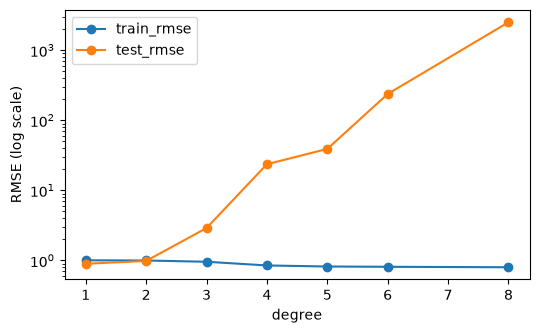

In [3]:
Xs, ys = Xtr.iloc[:30], ytr.iloc[:30]   # tiny training set makes overfitting visible
rows = []
for d in [1, 2, 3, 4, 5, 6, 8]:
    m = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression()).fit(Xs[['MedInc']], ys)
    rows.append((d, rmse(m, Xs[['MedInc']], ys), rmse(m, Xte[['MedInc']], yte)))
r = pd.DataFrame(rows, columns=['degree', 'train_rmse', 'test_rmse']).set_index('degree'); display(r.round(3)); r.plot(marker='o', figsize=(6, 3.5), logy=True); plt.ylabel('RMSE (log scale)'); plt.show()

With 30 training rows, train RMSE keeps falling as the degree rises, while test RMSE explodes: the polynomial passes through the training points but oscillates elsewhere. That gap is **overfitting**; degree 1-2 underfits/fits sensibly. (With all 4000 rows the curve stays flat because MedInc alone is a weak predictor.)

## 4. Regularized regression: Ridge (L2) and Lasso (L1) shrink coefficients

In [4]:
sc = StandardScaler().fit(Xtr); A, B = sc.transform(Xtr), sc.transform(Xte)
coefs = pd.DataFrame({'OLS': LinearRegression().fit(A, ytr).coef_, 'Ridge a=100': Ridge(100).fit(A, ytr).coef_, 'Lasso a=0.05': Lasso(0.05).fit(A, ytr).coef_}, index=X.columns).round(3); display(coefs)
print('Lasso zeroed features:', list(coefs.index[coefs['Lasso a=0.05'] == 0]))

,OLS,Ridge a=100,Lasso a=0.05
MedInc,0.851,0.819,0.733
HouseAge,0.159,0.177,0.145
AveRooms,-0.238,-0.176,-0.000
AveBedrms,0.295,0.219,0.004
Population,0.050,0.056,0.000
AveOccup,-0.190,-0.189,-0.151
Latitude,-0.909,-0.624,-0.244
Longitude,-0.867,-0.578,-0.187


Lasso zeroed features: ['AveRooms', 'Population']


## 5. Logistic regression: regression for classification (Titanic survival)
`P(y=1|x) = 1 / (1 + exp(-(w.x+b)))`: linear model in the log-odds.

In [5]:
from arena.evaluate import split
from arena.preprocess import build_preprocessor
from sklearn.metrics import accuracy_score
acc = []
for s in range(5):
    a, b, c, d = split('clf', s); pre, _ = build_preprocessor(a); m = LogisticRegression(max_iter=1000).fit(pre.fit_transform(a), c); acc.append(accuracy_score(d, m.predict(pre.transform(b))))
print('logistic regression accuracy over 5 seeds: %.3f +- %.3f' % (np.mean(acc), np.std(acc, ddof=1)))

logistic regression accuracy over 5 seeds: 0.830 +- 0.015


## When to use which
| Type | Use when | Risk |
|---|---|---|
| Simple linear | one dominant predictor, interpretability | ignores other features |
| Multiple linear | several roughly linear effects | multicollinearity, non-linearity |
| Polynomial | curved relationship in few features | overfitting at high degree |
| Ridge / Lasso | many/correlated features, need shrinkage / feature selection | needs alpha tuning |
| Logistic | binary target, want probabilities | linear decision boundary |